# Temperature model: is mean cell temperature log-linear in current density?

Step 1 of the optimization plan. The MATLAB optimizer (step 2) and the Monte Carlo robustness study (step 3) need a semi-empirical model for the mean cell temperature as a function of the operating point. The hypothesis to test is that temperature is **log-linear in current density**.

**Status**
- [x] **Hypothesis rejected.** `T = a + b·ln(j)` is 3x worse than a straight line and 7x worse than the selected model (cross-validated RMSE 0.66 K vs 0.20 K and 0.09 K), bends the wrong way, and diverges at low load. The other reading, `ln(T) = a + b·j`, is just a straight line in disguise over a 6 K range, and it breaks as soon as the coolant inlet temperature changes.
- [x] **The response to model is the rise above coolant inlet**, `ΔT = T_mean − T_coolant_in`. The inlet is controlled but wanders by ±1.5 K, and it moves `T_mean` one for one.
- [x] **Coolant flow matters, and it differs between tests.** Polarization curves ran at a fixed 6.0 L/min; the sensitivity tests ran at 6 to 8 L/min. This explains why the sensitivity holds sit 0.3 to 0.6 K cooler at the same current.
- [x] **Selected model** (cross-validated RMSE 0.09 K across 19 test groups): `ΔT = a + b·j·(6/F_cl) + c·j² + d·(T_in − 70) + e·age`. The flow coefficient fitted on the sensitivity data alone matches the pooled fit within about 1 %.
- [x] Coefficients, bootstrap uncertainty and residual noise exported to `MATLAB/data/thermal_params.csv` for steps 2 and 3.

**Run order:** `load_data.py` → this notebook (builds table `thermal_holds` from the raw tables on first run, ~2 to 3 min).

In [ ]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from contextlib import closing

HERE = os.getcwd()
PROJECT_DIR = os.path.dirname(HERE)
DB_path = os.path.join(PROJECT_DIR, "cathode_degradation.db")
OUT_DIR = os.path.join(PROJECT_DIR, "MATLAB")
REBUILD = False          # True: re-extract thermal_holds from the raw tables
N_CELLS, AREA = 10, 280.0
pd.set_option("display.width", 200)

def q(sql):
    with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
        return pd.read_sql_query(sql, con)

tables = q("SELECT name FROM sqlite_master WHERE type='table'").name.tolist()
print("thermal_holds present:", "thermal_holds" in tables)

thermal_holds present: False


## 1. Data: steady-state holds with the coolant side

`steady_state` has the cell temperatures but not the coolant loop. This cell repeats the same hold detection (setpoint change > 0.5 A starts a new hold, holds shorter than 60 s skipped, last 60 s averaged) and adds coolant flow `F_cl`, coolant inlet and outlet temperature, and two equilibrium checks: the temperature slope over the averaging window (`dTdt_Kmin`) and the mean temperature over the first 60 s of the hold.

In [2]:
TMP = [f"Temperature_{i}" for i in range(180)]
COLS = {"I_set": "I.S.set [A]", "j": "j.S.act [A/cm2]", "I": "I.S.act [A]", "U": "U.S.AveCell [V]",
        "F_cl": "F.Si.CL [l/min]", "F_cl_set": "F.Si.CL.set [l/min]", "T_cl_in": "T.Si.CL [°C]",
        "T_cl_out": "T.So.CL [°C]", "p_c": "p.So.C [kPag]", "lam_c": "Stoic.S.C [-]",
        "T_c_in": "T.Si.C [°C]", "T_c_out": "T.So.C [°C]", "F_air": "F.Si.Air.C [nl/min]"}
TOL, MIN_HOLD, WINDOW = 0.5, 60, 60

def extract_holds():
    sel = ",".join(f'"{c}"' for c in list(COLS.values()) + TMP)
    rows = []
    with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
        groups = [("polarization_raw", f"age_h={a} AND air_air_start={b}",
                   dict(dataset="polarization", age_h=a, air_air_start=b, parameter=None))
                  for a, b in con.execute("SELECT DISTINCT age_h, air_air_start FROM polarization_raw ORDER BY 1, 2")]
        groups += [("sensitivity_raw", f"age_h={a} AND parameter='{p}'",
                    dict(dataset="sensitivity", age_h=a, air_air_start=None, parameter=p))
                   for a, p in con.execute("SELECT DISTINCT age_h, parameter FROM sensitivity_raw ORDER BY 1, 2")]
        for tbl, where, ident in groups:
            df = pd.read_sql_query(f"SELECT {sel} FROM {tbl} WHERE {where}", con)
            df = df.rename(columns={v: k for k, v in COLS.items()})
            T = df[TMP].where((df[TMP] > 30) & (df[TMP] < 100))        # drop dead/implausible sensors
            df["T_mean"], df["T_std"] = T.mean(axis=1), T.std(axis=1, ddof=0)
            s = df.I_set.values
            bounds = [0] + [i for i in range(1, len(s)) if abs(s[i] - s[i-1]) > TOL] + [len(s)]
            k = 0
            for lo, hi in zip(bounds[:-1], bounds[1:]):
                if hi - lo < MIN_HOLD:
                    continue
                w = df.iloc[max(lo, hi - WINDOW):hi]
                r = dict(ident, hold_index=k, hold_len_s=hi - lo); k += 1
                for c in list(COLS) + ["T_mean", "T_std"]:
                    r[c] = w[c].mean()
                r["dTdt_Kmin"] = np.polyfit(np.arange(len(w)), w.T_mean.values, 1)[0] * 60
                r["T_mean_first60"] = df.T_mean.iloc[lo:lo + 60].mean()
                rows.append(r)
            print(f"  {ident['dataset']:12} {ident['parameter'] or ('airair' if ident['air_air_start'] else 'nominal'):12}"
                  f" age {ident['age_h']:>4}: {k:>3} holds")
    return pd.DataFrame(rows)

if REBUILD or "thermal_holds" not in tables:
    H = extract_holds()
    with closing(sqlite3.connect(DB_path)) as con:
        H.to_sql("thermal_holds", con, index=False, if_exists="replace")
    print(f"thermal_holds: {len(H)} rows written")
H = q("SELECT * FROM thermal_holds")
print(H.shape)

  polarization nominal      age    0:  35 holds
  polarization nominal      age  300:  33 holds
  polarization nominal      age  600:  33 holds
  polarization nominal      age  850:  32 holds
  polarization nominal      age 1150:  33 holds
  polarization nominal      age 1500:  32 holds
  polarization airair       age 1500:  32 holds
  polarization nominal      age 1750:  33 holds
  polarization nominal      age 2000:  32 holds
  polarization nominal      age 2300:  33 holds
  polarization airair       age 2300:  32 holds
  sensitivity  Humidity     age    0:  20 holds
  sensitivity  Pressure     age    0:  22 holds
  sensitivity  Stoic        age    0:  15 holds
  sensitivity  Temperature  age    0:  23 holds
  sensitivity  Humidity     age 2300:  16 holds
  sensitivity  Pressure     age 2300:  15 holds
  sensitivity  Stoic        age 2300:  15 holds
  sensitivity  Temperature  age 2300:  26 holds
thermal_holds: 512 rows written
(512, 23)


In [3]:
# modelling set: loaded holds at normal pressure (drops open circuit and the final shutdown hold at 22 kPaG)
D = H[(H.j > 0.02) & (H.p_c > 40)].copy()
D["dT"] = D.T_mean - D.T_cl_in
D["g"] = 6.0 / D.F_cl                       # coolant flow relative to the 6 L/min polarization setting
D["Tin"] = D.T_cl_in - 70.0
D["age"] = D.age_h / 1000.0
D["grp"] = (D.dataset + " " + D.age_h.astype(str) + " " + D.parameter.fillna("")
            + np.where(D.air_air_start == 1, "air/air", ""))
print(len(D), "holds in", D.grp.nunique(), "test groups")
D.groupby("dataset").agg(n=("j", "size"), F_cl_mean=("F_cl", "mean"), F_cl_min=("F_cl", "min"),
                         F_cl_max=("F_cl", "max"), hold_len_median_s=("hold_len_s", "median")).round(2)

497 holds in 19 test groups


,n,F_cl_mean,F_cl_min,F_cl_max,hold_len_median_s
dataset,,,,,
polarization,348,6.00,5.97,6.02,302.0
sensitivity,149,7.18,5.98,8.05,304.0


## 2. Testing the hypothesis

Two readings of "log-linear in current density":
- **(a)** `T = a + b·ln(j)`: temperature grows with the logarithm of the load.
- **(b)** `ln(T) = a + b·j`: the log of temperature is linear in load (log-linear regression in the statistical sense).

Both are fitted to `ΔT` (or `T_mean` for (b), in kelvin), next to a straight line and a quadratic. The left panel shows BoL with its two coolant flows; the right panel shows the residuals of each model against current density for all polarization holds.

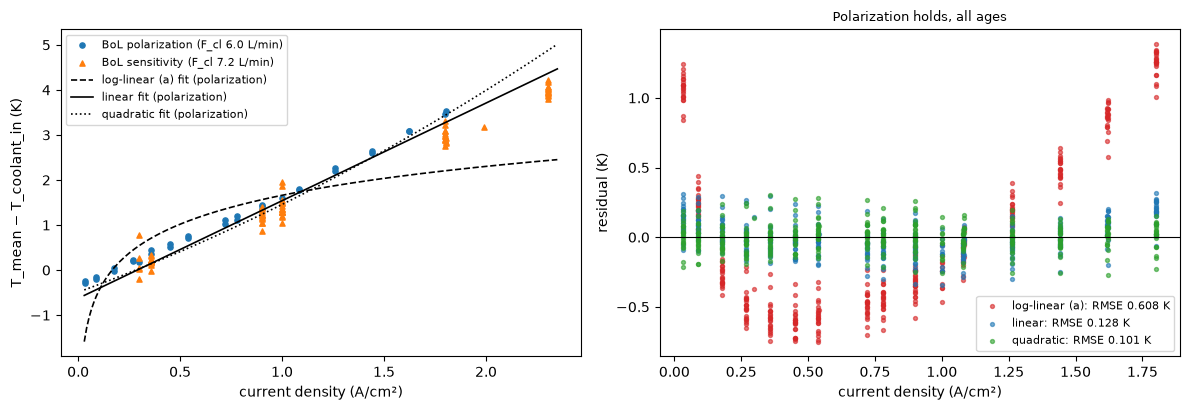

In [4]:
def lstsq(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

pol = D[D.dataset == "polarization"]
jj = np.linspace(0.03, 2.35, 200)
cand = {"log-linear (a)": lambda j: np.c_[np.ones_like(j), np.log(j)],
        "linear": lambda j: np.c_[np.ones_like(j), j],
        "quadratic": lambda j: np.c_[np.ones_like(j), j, j**2]}
coef = {n: lstsq(f(pol.j.values), pol.dT.values) for n, f in cand.items()}

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
b0 = D[D.age_h == 0]
for ds, mk in (("polarization", "o"), ("sensitivity", "^")):
    g = b0[b0.dataset == ds]
    axs[0].scatter(g.j, g.dT, s=14, marker=mk, label=f"BoL {ds} (F_cl {g.F_cl.mean():.1f} L/min)")
for (n, f), ls in zip(cand.items(), ("--", "-", ":")):
    axs[0].plot(jj, f(jj) @ coef[n], ls, color="k", lw=1.2, label=f"{n} fit (polarization)")
axs[0].set_xlabel("current density (A/cm²)"); axs[0].set_ylabel("T_mean − T_coolant_in (K)")
axs[0].legend(fontsize=8)
for (n, f), c in zip(cand.items(), ("C3", "C0", "C2")):
    r = pol.dT.values - f(pol.j.values) @ coef[n]
    axs[1].scatter(pol.j, r, s=8, color=c, alpha=0.6, label=f"{n}: RMSE {np.sqrt((r**2).mean()):.3f} K")
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xlabel("current density (A/cm²)"); axs[1].set_ylabel("residual (K)")
axs[1].set_title("Polarization holds, all ages", fontsize=9); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The log-linear curve is concave: it rises fastest at low load and flattens at high load, so it overshoots in the middle and undershoots at both ends. The data do the opposite. Waste heat is `q = j·(E_tn − U(j))`, and since cell voltage falls with load, heat grows slightly **faster** than linearly. The logarithm also goes to minus infinity as `j → 0`, while the measured rise goes smoothly to about −0.5 K (the cells sit just below coolant inlet at idle).

### Cross-validated comparison

Leave one test group out (19 groups: each polarization curve, each air/air curve, each sensitivity sweep), fit on the rest, predict the held-out group. This is the honest test for the optimizer, which will query operating points between and beyond the training holds.

In [5]:
y = D.dT.values
MODELS = {
    "log-linear (a): a + b·ln j":                  lambda D: np.c_[np.ones(len(D)), np.log(D.j)],
    "linear: a + b·j":                             lambda D: np.c_[np.ones(len(D)), D.j],
    "quadratic: a + b·j + c·j²":                   lambda D: np.c_[np.ones(len(D)), D.j, D.j**2],
    "heat: a + b·j(1.254 − U)":                    lambda D: np.c_[np.ones(len(D)), D.j * (1.254 - D.U)],
    "+ flow: a + b·j·g + c·j²":                    lambda D: np.c_[np.ones(len(D)), D.j*D.g, D.j**2],
    "+ inlet T: ... + d·(T_in − 70)":              lambda D: np.c_[np.ones(len(D)), D.j*D.g, D.j**2, D.Tin],
    "+ age: ... + e·age  (selected)":              lambda D: np.c_[np.ones(len(D)), D.j*D.g, D.j**2, D.Tin, D.age],
    "heat + flow + inlet T + age":                 lambda D: np.c_[np.ones(len(D)), D.j*(1.254-D.U)*D.g, D.Tin, D.age],
}

def logo(X, y, groups):
    e = np.zeros(len(y))
    for gname in np.unique(groups):
        te = groups == gname
        e[te] = y[te] - X[te] @ lstsq(X[~te], y[~te])
    return e

grp, sens = D.grp.values, (D.dataset == "sensitivity").values
rows = []
for name, f in MODELS.items():
    X = f(D); r = y - X @ lstsq(X, y); e = logo(X, y, grp)
    rows.append({"model": name, "k": X.shape[1], "fit RMSE": np.sqrt((r**2).mean()),
                 "LOGO RMSE": np.sqrt((e**2).mean()), "LOGO polarization": np.sqrt((e[~sens]**2).mean()),
                 "LOGO sensitivity": np.sqrt((e[sens]**2).mean())})
# reading (b): ln(T_mean [K]) = a + b j, judged on T_mean
Xb = np.c_[np.ones(len(D)), D.j]; yb = np.log(D.T_mean.values + 273.15)
eb = np.zeros(len(D))
for gname in np.unique(grp):
    te = grp == gname
    eb[te] = D.T_mean.values[te] - (np.exp(Xb[te] @ lstsq(Xb[~te], yb[~te])) - 273.15)
rb = D.T_mean.values - (np.exp(Xb @ lstsq(Xb, yb)) - 273.15)
rows.insert(1, {"model": "log-linear (b): ln T = a + b·j", "k": 2, "fit RMSE": np.sqrt((rb**2).mean()),
                "LOGO RMSE": np.sqrt((eb**2).mean()), "LOGO polarization": np.sqrt((eb[~sens]**2).mean()),
                "LOGO sensitivity": np.sqrt((eb[sens]**2).mean())})
cmp = pd.DataFrame(rows).set_index("model").round(3)
cmp

,k,fit RMSE,LOGO RMSE,LOGO polarization,LOGO sensitivity
model,,,,,
log-linear (a): a + b·ln j,2,0.657,0.663,0.628,0.738
log-linear (b): ln T = a + b·j,2,2.880,2.932,0.840,5.198
linear: a + b·j,2,0.195,0.202,0.168,0.266
quadratic: a + b·j + c·j²,3,0.195,0.202,0.168,0.266
heat: a + b·j(1.254 − U),2,0.252,0.265,0.213,0.358
+ flow: a + b·j·g + c·j²,3,0.137,0.143,0.108,0.202
+ inlet T: ... + d·(T_in − 70),4,0.128,0.138,0.108,0.191
+ age: ... + e·age (selected),5,0.086,0.094,0.062,0.144
heat + flow + inlet T + age,4,0.106,0.113,0.068,0.178


- **Reading (a)** fails on every test: 3x the error of a line, and the residual pattern above is systematic, not noise.
- **Reading (b)** looks fine inside one polarization curve (a log of something that varies by only 6 K out of 343 K is a straight line), but it has no way to follow the coolant inlet. When the temperature sweep (55 to 75 °C) is held out, it misses by several kelvin.
- **Linear vs quadratic.** Without a coolant-flow term the quadratic term vanishes: the highest loads in the sensitivity tests ran at 8 L/min, which pulls their temperatures down and hides the curvature. Once flow enters the model (below), the quadratic term becomes clearly significant.
- **Linear vs heat-based.** Using the waste heat `j·(1.254 − U)` as the driver fits the polarization curves slightly better but predicts the sensitivity tests worse than plain current. The next cell shows why.

## 3. What actually sets the temperature rise

### Energy balance on the coolant loop

Heat removed by the coolant, `Q_cl = ρ·c_p·F_cl·(T_out − T_in)` (water assumed), against the electrochemical waste heat `Q_gen = N·I·(E_tn − U)` with `E_tn` = 1.254 V (product as vapour, LHV) or 1.481 V (liquid, HHV). The coolant heat falls mostly between the two lines, as expected when part of the product water leaves as vapour. The coolant flow reading and the assumed c_p carry a few percent of uncertainty, so this is a plausibility check, not a closed balance.

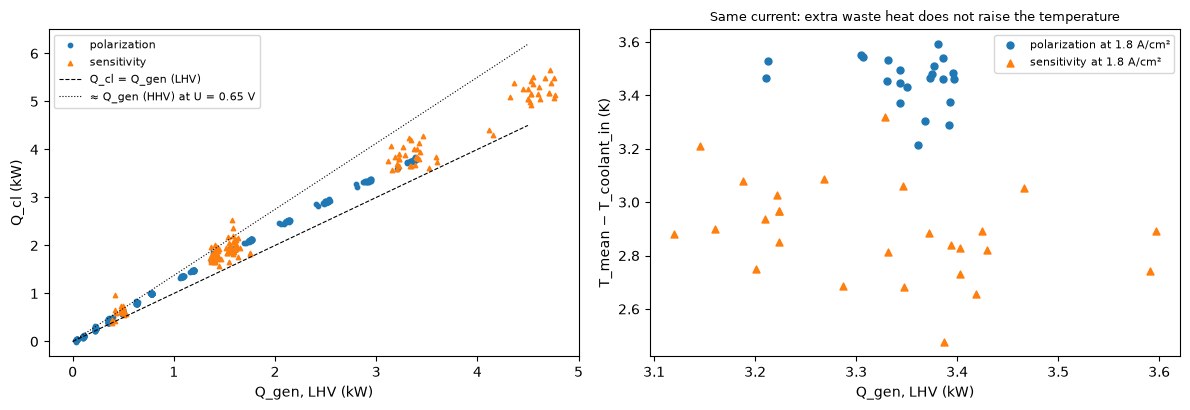

,age_h,parameter,U,Q_lhv,Q_cl,F_cl,T_cl_in
363,0,Humidity,0.62,3223.48,3654.48,7.37,70.25
368,0,Humidity,0.62,3187.68,3851.15,7.35,70.55
376,0,Humidity,0.63,3145.32,4076.52,7.38,70.22
384,0,Pressure,0.54,3596.76,3729.90,7.26,70.02
389,0,Pressure,0.59,3331.60,3659.55,7.30,70.42
394,0,Pressure,0.64,3119.51,3762.82,7.29,70.30
399,0,Pressure,0.61,3223.57,3797.39,7.32,70.20
405,0,Stoic,0.61,3223.57,3797.39,7.32,70.20
410,0,Stoic,0.63,3160.47,3568.31,7.01,70.31
414,0,Stoic,0.62,3210.02,3704.74,7.08,70.71


In [6]:
A_ = H[(H.j > 0.02) & (H.p_c > 40)].copy()
A_["Q_cl"] = 978 * 4190 * A_.F_cl / 60000 * (A_.T_cl_out - A_.T_cl_in)
A_["Q_lhv"] = N_CELLS * A_.I * (1.254 - A_.U)
A_["Q_hhv"] = N_CELLS * A_.I * (1.481 - A_.U)
h18 = A_[(A_.j - 1.8).abs() < 0.05]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ds, mk in (("polarization", "o"), ("sensitivity", "^")):
    g = A_[A_.dataset == ds]
    axs[0].scatter(g.Q_lhv/1e3, g.Q_cl/1e3, s=10, marker=mk, label=ds)
m = np.array([0, 4.5])
axs[0].plot(m, m, "k--", lw=0.8, label="Q_cl = Q_gen (LHV)")
axs[0].plot(m, m * (1.481 - 0.65) / (1.254 - 0.65), "k:", lw=0.8, label="≈ Q_gen (HHV) at U = 0.65 V")
axs[0].set_xlabel("Q_gen, LHV (kW)"); axs[0].set_ylabel("Q_cl (kW)"); axs[0].legend(fontsize=8)
for ds, mk in (("polarization", "o"), ("sensitivity", "^")):
    g = h18[h18.dataset == ds]
    axs[1].scatter(g.Q_lhv/1e3, g.T_mean - g.T_cl_in, marker=mk, s=25, label=f"{ds} at 1.8 A/cm²")
axs[1].set_xlabel("Q_gen, LHV (kW)"); axs[1].set_ylabel("T_mean − T_coolant_in (K)")
axs[1].set_title("Same current: extra waste heat does not raise the temperature", fontsize=9)
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
h18[h18.dataset == "sensitivity"][["age_h", "parameter", "U", "Q_lhv", "Q_cl", "F_cl", "T_cl_in"]].round(2)

At a fixed 1.8 A/cm², the sensitivity holds span 3.1 to 3.6 kW of waste heat (low pressure and aging lower the voltage), yet the temperature rise and the coolant heat stay flat. The extra loss at low pressure leaves mainly with the exhaust gas as evaporated water, not through the coolant. This is why current density, not waste heat, is the better driver for the cell temperature in this stack.

### Coolant flow: confirmed within the sensitivity data

The flow term `j·(6/F_cl)` follows from the coolant rise `ΔT_cl ∝ Q/(ṁ·c_p)`. Polarization holds all ran at 6 L/min, so the flow effect is identified by the sensitivity tests (6 to 8 L/min). Fitting the selected model on the sensitivity holds alone gives the same coefficients as the pooled fit, so this is a real flow effect, not an offset between test types.

In [7]:
sel = MODELS["+ age: ... + e·age  (selected)"]
names = ["a", "b (j·6/F_cl)", "c (j²)", "d (T_in − 70)", "e (age, per 1000 h)"]
pd.DataFrame({"pooled (all holds)": lstsq(sel(D), y), "sensitivity holds only": lstsq(sel(D[sens]), y[sens])},
             index=names).round(3)

,pooled (all holds),sensitivity holds only
a,-0.369,-0.387
b (j·6/F_cl),1.683,1.663
c (j²),0.277,0.285
d (T_in − 70),-0.015,-0.017
"e (age, per 1000 h)",-0.106,-0.102


## 4. Selected semi-empirical model

$$T_{mean} = T_{in} + a + b\,j\,\frac{6}{F_{cl}} + c\,j^2 + d\,(T_{in} - 70) + e\,\frac{t}{1000\,\mathrm{h}}$$

- `b·j·6/F_cl`: coolant temperature rise, inversely proportional to coolant flow (L/min).
- `c·j²`: convexity from the voltage loss growing with load (more heat per ampere at high current).
- `d·(T_in − 70)`: a hotter stack sheds more heat through evaporation into the gas streams, so the rise shrinks slightly.
- `e·t`: a small downward drift (−0.1 K per 1000 h). Aging produces more heat, not less, so this is most likely sensor drift on the measurement board. It is kept so the residuals are clean, and it can be set to zero for an "as-built" stack.

Parameter uncertainty comes from a group bootstrap (resampling whole test groups, 2000 times), which keeps the correlation between holds of the same curve.

In [8]:
X = sel(D); beta = lstsq(X, y); res = y - X @ beta
rng = np.random.default_rng(0)
G = np.unique(grp); idx = {gname: np.where(grp == gname)[0] for gname in G}
boot = []
for _ in range(2000):
    ii = np.concatenate([idx[gname] for gname in rng.choice(G, len(G))])
    boot.append(lstsq(X[ii], y[ii]))
boot = np.array(boot)
e_logo = logo(X, y, grp)
units = ["K", "K per A/cm² at 6 L/min", "K per (A/cm²)²", "K per K", "K per 1000 h"]
params = pd.DataFrame({"value": beta, "boot_se": boot.std(axis=0),
                       "ci95_lo": np.percentile(boot, 2.5, axis=0), "ci95_hi": np.percentile(boot, 97.5, axis=0),
                       "unit": units}, index=names)
print(f"residual RMSE {np.sqrt((res**2).mean()):.3f} K | cross-validated (LOGO) {np.sqrt((e_logo**2).mean()):.3f} K")
params.round(4)

residual RMSE 0.086 K | cross-validated (LOGO) 0.094 K


,value,boot_se,ci95_lo,ci95_hi,unit
a,-0.3687,0.0262,-0.4215,-0.3206,K
b (j·6/F_cl),1.6828,0.0240,1.6279,1.7218,K per A/cm² at 6 L/min
c (j²),0.2772,0.0121,0.2595,0.3069,K per (A/cm²)²
d (T_in − 70),-0.0154,0.0070,-0.0377,-0.0093,K per K
"e (age, per 1000 h)",-0.1059,0.0148,-0.1324,-0.0749,K per 1000 h


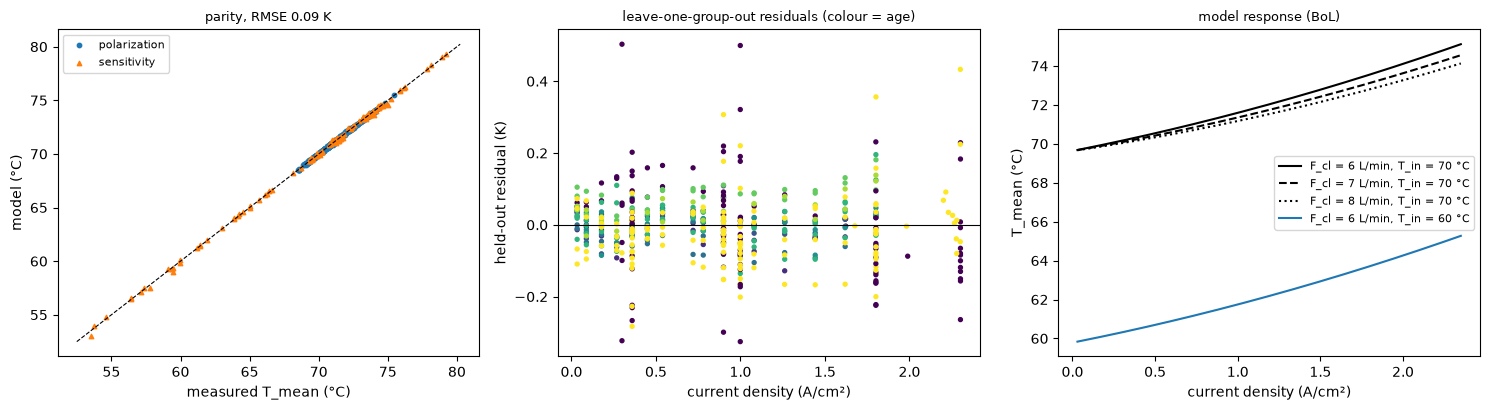

In [9]:
def T_mean_model(j, F_cl=6.0, T_in=70.0, age_h=0.0, p=beta):
    """Mean cell temperature (°C) from current density (A/cm²), coolant flow (L/min), coolant inlet (°C), age (h)."""
    j = np.asarray(j, float)
    return T_in + p[0] + p[1]*j*6.0/F_cl + p[2]*j**2 + p[3]*(T_in - 70.0) + p[4]*age_h/1000.0

D["T_pred"] = T_mean_model(D.j, D.F_cl, D.T_cl_in, D.age_h)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ds, mk in (("polarization", "o"), ("sensitivity", "^")):
    g = D[D.dataset == ds]
    axs[0].scatter(g.T_mean, g.T_pred, s=10, marker=mk, label=ds)
lim = [D.T_mean.min() - 1, D.T_mean.max() + 1]
axs[0].plot(lim, lim, "k--", lw=0.8); axs[0].set_xlabel("measured T_mean (°C)"); axs[0].set_ylabel("model (°C)")
axs[0].legend(fontsize=8); axs[0].set_title(f"parity, RMSE {np.sqrt((res**2).mean()):.2f} K", fontsize=9)
axs[1].scatter(D.j, e_logo, s=8, c=D.age_h, cmap="viridis")
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xlabel("current density (A/cm²)")
axs[1].set_ylabel("held-out residual (K)"); axs[1].set_title("leave-one-group-out residuals (colour = age)", fontsize=9)
for F_, ls in ((6, "-"), (7, "--"), (8, ":")):
    axs[2].plot(jj, T_mean_model(jj, F_, 70.0), ls, color="k", label=f"F_cl = {F_} L/min, T_in = 70 °C")
axs[2].plot(jj, T_mean_model(jj, 6, 60.0), "-", color="C0", label="F_cl = 6 L/min, T_in = 60 °C")
axs[2].set_xlabel("current density (A/cm²)"); axs[2].set_ylabel("T_mean (°C)"); axs[2].legend(fontsize=8)
axs[2].set_title("model response (BoL)", fontsize=9)
plt.tight_layout(); plt.show()

### Checks: thermal equilibrium and air/air curves

Holds are 2 min (low load) to 5 min. If the stack had not settled, short holds would carry a bias and the window slope `dTdt_Kmin` would be large.

In [10]:
D["res"] = res
D["hold"] = pd.cut(D.hold_len_s, [0, 150, 400, 1e5], labels=["≤150 s", "150–400 s", ">400 s"])
display(D.groupby("hold", observed=True).agg(n=("res", "size"), mean_res_K=("res", "mean"), rmse_K=("res", lambda v: np.sqrt((v**2).mean())),
                                             median_abs_dTdt_Kmin=("dTdt_Kmin", lambda v: v.abs().median())).round(3))
D.groupby(D.air_air_start.fillna(0).astype(int)).agg(n=("res", "size"), mean_res_K=("res", "mean")).round(3)

,n,mean_res_K,rmse_K,median_abs_dTdt_Kmin
hold,,,,
≤150 s,98,0.005,0.069,0.110
150–400 s,356,0.002,0.084,0.172
>400 s,43,-0.032,0.130,0.074


,n,mean_res_K
air_air_start,,
0,435,0.004
1,62,-0.029


Residuals are unbiased across hold lengths, and the temperature drifts by only ~0.1 to 0.2 K/min inside the averaging window, so the holds are close enough to equilibrium for a steady-state model. The two air/air-start curves sit about 0.03 K cooler than the nominal ones, well inside the noise, so no separate term.

### Temperature spread across the plate

The Monte Carlo study may also want the in-plane spread. The same structure fits `T_std` (standard deviation over the 180 plate sensors) well.

In [11]:
ys = D.T_std.values
beta_s = lstsq(X, ys); es = logo(X, ys, grp)
print(f"T_std model: residual RMSE {np.sqrt(((ys - X @ beta_s)**2).mean()):.3f} K, LOGO {np.sqrt((es**2).mean()):.3f} K")
pd.Series(beta_s, index=names).round(4)

T_std model: residual RMSE 0.051 K, LOGO 0.052 K


a                      0.2463
b (j·6/F_cl)           1.0655
c (j²)                 0.0871
d (T_in − 70)          0.0035
e (age, per 1000 h)    0.0048
dtype: float64

## 5. Export for MATLAB (steps 2 and 3)

`MATLAB/data/thermal_params.csv` holds the coefficients, their bootstrap standard errors, and the residual noise to add in the Monte Carlo runs. The full bootstrap draws go to `thermal_params_boot.csv`, so the Monte Carlo can sample correlated parameter sets instead of independent ones.

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
keys = ["a", "b_flow", "c_j2", "d_Tin", "e_age"]
out = pd.DataFrame({"name": keys + ["sigma_res_K", "sigma_logo_K", "s_a", "s_b_flow", "s_c_j2", "s_d_Tin", "s_e_age"],
                    "value": list(beta) + [np.sqrt((res**2).mean()), np.sqrt((e_logo**2).mean())] + list(beta_s),
                    "boot_se": list(boot.std(axis=0)) + [np.nan, np.nan] + [np.nan]*5,
                    "unit": units + ["K", "K"] + ["K (T_std model)"]*5})
out.to_csv(os.path.join(OUT_DIR, "thermal_params.csv"), index=False)
pd.DataFrame(boot, columns=keys).to_csv(os.path.join(OUT_DIR, "thermal_params_boot.csv"), index=False)
print("MATLAB form:")
print(f"T_mean = T_in + ({beta[0]:.4f}) + ({beta[1]:.4f})*j*6/F_cl + ({beta[2]:.4f})*j^2 "
      f"+ ({beta[3]:.4f})*(T_in-70) + ({beta[4]:.4f})*age_h/1000")
out.round(4)

MATLAB form:
T_mean = T_in + (-0.3687) + (1.6828)*j*6/F_cl + (0.2772)*j^2 + (-0.0154)*(T_in-70) + (-0.1059)*age_h/1000


,name,value,boot_se,unit
0,a,-0.3687,0.0262,K
1,b_flow,1.6828,0.0240,K per A/cm² at 6 L/min
2,c_j2,0.2772,0.0121,K per (A/cm²)²
3,d_Tin,-0.0154,0.0070,K per K
4,e_age,-0.1059,0.0148,K per 1000 h
5,sigma_res_K,0.0863,NaN,K
6,sigma_logo_K,0.0943,NaN,K
7,s_a,0.2463,NaN,K (T_std model)
8,s_b_flow,1.0655,NaN,K (T_std model)
9,s_c_j2,0.0871,NaN,K (T_std model)


## 6. Findings

| Question | Answer |
|---|---|
| Is T log-linear in j? | No. `a + b·ln j` gives 0.66 K cross-validated error vs 0.09 K for the selected model, bends the wrong way, and diverges at idle. `ln T` linear in j is a straight line in disguise and cannot follow the coolant inlet. |
| What to model | the rise above coolant inlet, `T_mean − T_in` |
| Main driver | current density, through the coolant rise (`∝ j/F_cl`) plus a small quadratic term |
| Coolant flow | real effect: 6 → 8 L/min lowers the rise at 1.8 A/cm² by about 0.75 K |
| Coolant inlet | each +10 K at the inlet shrinks the rise by ~0.15 K (more evaporative cooling) |
| Waste heat as driver | worse out of sample: at fixed current the extra loss from low pressure or aging leaves with the exhaust water, not the coolant |
| Residual noise for Monte Carlo | 0.09 K (cross-validated) |

**For step 2 (MATLAB).** Coolant flow and inlet temperature are both in the model, so the optimizer can trade pump power against stack temperature. The cell temperature range the data support is roughly 55 to 80 °C with flows of 6 to 8 L/min; outside that the model is extrapolating.

**Caveat.** Coolant heat is computed for water; if the loop runs a glycol mix, `Q_cl` is about 10 to 15 % lower, which does not affect the temperature model itself.